# T07 — Several participants at book level

*How do I simulate several traders against each other?*

**What you will learn**

- how several traders send orders to the order book of one contract, each under its own participant number;
- what each trader sees of its own orders and trades, and what it does not see;
- how to turn the book's trade records into each trader's cash and position;
- how to check that cash and positions are zero-sum: every euro one trader pays, another receives;
- why a trader can trade with itself.

**What you need**

- Previous tutorials: [T01 — Your first contract](T01_first_contract.ipynb) and
  [T02 — Order types and matching](T02_order_types.ipynb) (linked, not required).
- Run time: under 1 minute on a central processing unit (CPU). Most of it is the first call, which compiles the matching code.
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


## 1. One book, three traders

OMIE (Operador del Mercado Ibérico de Energía) runs the continuous intraday market (CID) of Spain and
Portugal. As in [T01](T01_first_contract.ipynb), we trade contract 52: power delivered from 13:00 to
13:15, with gate closure at 12:00. Prices are in euros per megawatt-hour (EUR/MWh) and quantities in
megawatts (MW).

> **Concept — several participants at book level.** A `Session` replays the orders of other traders and
> lets **one** participant send its own orders between them (see [Sessions](../docs/sessions.md)). To
> let several traders act against each other, work one level down, on the order book itself
> (`ContractBook`). Every order carries a participant number, `agent_id`. The book matches orders by
> price and time only; it never looks at who sent them.

The package has no public helper to open a contract, so we make an open copy with
`dataclasses.replace`. At book level, the caller gives each order an identifier and a timestamp. The
helper `submit` keeps both counters (orders arrive 5 seconds apart from 10:00:00; a timestamp is the
number of seconds after midnight of the delivery day). It also records every order it sends, which we
use for a check in section 5. Our three traders are participants 1, 2 and 3.

In [2]:
import dataclasses

from omiecid_simulator.omiecid.contract import ContractStatus, generate_contracts
from omiecid_simulator.omiecid.contract_book import ContractBook
from omiecid_simulator.omiecid.order_types import Side, make_order

contract = dataclasses.replace(generate_contracts()[52], status=ContractStatus.OPEN)  # no public "open" helper
book = ContractBook(contract)
state = book.init()  # the book is a value: every call returns a new state
TRADERS = (1, 2, 3)
counter = {"order_id": 0, "time": 10 * 3600}  # first order at 10:00:00
sent = []  # (order id, trader, side, MW) of every order sent, for the check of section 5


def submit(state, trader, side, price, qty):
    # Give the order the next id and a timestamp 5 s after the previous one, then submit it for `trader`.
    counter["order_id"] += 1
    counter["time"] += 5
    order = make_order(contract.contract_id, side, float(price), float(qty), counter["order_id"],
                       trader, counter["time"])
    sent.append((order.order_id, trader, side, order.quantity))
    return book.submit_order(state, order)


def clock(seconds):
    # Seconds after midnight as a clock time.
    return f"{seconds // 3600:02d}:{seconds // 60 % 60:02d}:{seconds % 60:02d}"


print(f"contract {contract.contract_id}, status {contract.status.name}, traders {TRADERS}")

contract 52, status OPEN, traders (1, 2, 3)


## 2. A first trade between two traders

Trader 1 offers 3 MW at 52.00 EUR/MWh. Trader 2 then bids for 2 MW at up to 52.10 EUR/MWh. The bid
crosses the ask, so 2 MW trade at once, at the price of the order that was waiting: 52.00 EUR/MWh.

Each trader can list its own trades with `get_agent_trades`. Each row is a price, a quantity and a time.

In [3]:
state, _ = submit(state, 1, Side.SELL, 52.00, 3)
state, result = submit(state, 2, Side.BUY, 52.10, 2)
print(f"trader 2's buy traded {float(result.trade_qty):.1f} MW at {float(result.trade_price):.2f} EUR/MWh")
for trader in (1, 2):
    for price, qty, ts in book.get_agent_trades(state, trader):
        print(f"   trader {trader} sees: {qty:.1f} MW at {price:.2f} EUR/MWh, at {clock(ts)}")

trader 2's buy traded 2.0 MW at 52.00 EUR/MWh
   trader 1 sees: 2.0 MW at 52.00 EUR/MWh, at 10:00:10
   trader 2 sees: 2.0 MW at 52.00 EUR/MWh, at 10:00:10


Both traders see the same row. It does not name the other side, and in OMIE it would not either: during
trading, a participant does not learn its counterparty. (OMIE publishes the bidding units of both sides
of each trade about 90 days later, in its public trade file; in a cross-border trade the non-Iberian side is left blank.) It also does not say who bought. Here OMIE's notification
differs: it tells the participant the side of its own order in the trade, but this version of
`get_agent_trades` leaves the side out ([certificate, gap table](../docs/omiecid/certificate.md#conformance-gaps)).
A trader can recover its side from its own order. But to settle several traders at once we need the
buyer and the seller of every trade. Section 5 reads them from the book's own trade records.

## 3. Thirty-six more orders

Now the three traders send 36 more limit orders. The helper `random_flow` draws, for each order, a
trader, a side, a price from 51.60 to 52.40 EUR/MWh in steps of 0.10, and a quantity from 1 to 5 MW.
The flow has its own fixed seed, so a re-run sends the same orders. Some orders cross the book and trade at once;
the others rest in it. `show_book` prints the anonymous book, as in T01.

In [4]:
def random_flow(state, rng, n):
    # n limit orders, each with a random trader, side, price (51.60 to 52.40 EUR/MWh, step 0.10) and size (1 to 5 MW).
    for _ in range(n):
        trader = int(rng.choice(TRADERS))
        side = Side.BUY if rng.random() < 0.5 else Side.SELL
        cents = 5200 + 10 * int(rng.integers(-4, 5))  # a whole number of cents, so the price is exact
        state, _ = submit(state, trader, side, cents / 100, int(rng.integers(1, 6)))
    return state


def show_book(state):
    # Print the anonymous book: asks from the highest price down, then bids from the highest down.
    bids, asks = book.get_anonymous_lob(state)
    for price, qty in sorted(asks, reverse=True):
        print(f"   ask  {price:6.2f} EUR/MWh  {qty:4.1f} MW")
    print("   " + "-" * 31)
    for price, qty in bids:
        print(f"   bid  {price:6.2f} EUR/MWh  {qty:4.1f} MW")


state = random_flow(state, np.random.default_rng(3), 36)  # the flow's own fixed seed
print(f"{len(sent)} orders sent in total; the book now reads:")
show_book(state)

38 orders sent in total; the book now reads:


   ask   52.40 EUR/MWh  16.0 MW
   ask   52.30 EUR/MWh   4.0 MW
   ask   52.20 EUR/MWh   2.0 MW
   -------------------------------
   bid   51.90 EUR/MWh   3.0 MW
   bid   51.80 EUR/MWh   3.0 MW
   bid   51.70 EUR/MWh   3.0 MW


## 4. Each trader's own view

In this simulator, a trader sees its own resting orders (`get_agent_orders`), its own trades
(`get_agent_trades`) and the anonymous book, and nothing else about the others. In OMIE a participant also
sees the price and the volume of the trades made in its area, without names (OMIE Rules §45.2.12). This
version offers no participant call for those. For an iceberg, the owner's view shows the full
quantity, hidden part included (see [T02](T02_order_types.ipynb)); here every order is a plain limit order.

In [5]:
for t in TRADERS:
    own = book.get_agent_orders(state, t)
    to_buy = sum(o.quantity for o in own if o.side == Side.BUY)
    to_sell = sum(o.quantity for o in own if o.side == Side.SELL)
    trades = book.get_agent_trades(state, t)
    print(f"trader {t}: {len(own)} resting order{'s' if len(own) != 1 else ''} ({to_buy:4.1f} MW to buy, {to_sell:4.1f} MW to sell); "
          f"{len(trades):2d} trades, {sum(q for _, q, _ in trades):5.1f} MW in total")

trader 1: 1 resting order ( 0.0 MW to buy,  4.0 MW to sell);  9 trades,  19.0 MW in total


trader 2: 8 resting orders ( 6.0 MW to buy,  7.0 MW to sell); 12 trades,  20.0 MW in total
trader 3: 5 resting orders ( 3.0 MW to buy, 11.0 MW to sell); 11 trades,  26.0 MW in total


The trades of one trader add up to a quantity, but without a side we cannot tell whether the trader
ended long or short.

## 5. The book's trade records: who bought, who sold

The book keeps one record per trade in `state.lob.trades`, an array of whole numbers with one row per
trade and 8 columns. This is internal state; [T08](T08_overseers_view.ipynb) looks at it in detail.
The column positions are named in `TradesFeat`, in the package's constants module.

> **Concept — trade record.** A trade record holds the price and the quantity, both in ticks (see
> [T01](T01_first_contract.ipynb)), the ids of the **passive** order (the one that was waiting) and of
> the **aggressor** (the one that arrived and traded at once), the time, and the participant numbers of
> both. It names the passive and the aggressive trader, not the buyer and the seller. The side comes
> from the sign of the quantity, which follows the aggressor: the quantity is **negative when the
> aggressor bought** and positive when it sold.

The package computes a trader's cash with `compute_agent_pnl`, from rows in another layout:
time, price ticks, quantity ticks, buyer, seller, contract. It has no converter from the book's
records to that layout, so `settlement_rows` below does it in 10 lines, with the side rule above.
Empty rows of the array hold $-1$; a real record always has a positive order id.

In [6]:
from omiecid_simulator.jaxob.jaxob_constants import TradesFeat
from omiecid_simulator.omiecid.encoding import decode_price, encode_qty
from omiecid_simulator.omiecid.omie_config import OMIEMarketConfig, OMIEProductConfig

cfg = OMIEProductConfig()  # ticks: 0.01 EUR/MWh and 0.1 MW
P, Q, SEC = TradesFeat.P.value, TradesFeat.Q.value, TradesFeat.SEC.value
PASS_OID, PASS_TID, AGRS_TID = TradesFeat.PASS_OID.value, TradesFeat.PASS_TID.value, TradesFeat.AGRS_TID.value


def settlement_rows(state):
    # The book's trade records (8 columns) -> the layout of compute_agent_pnl (6 columns):
    # [time, price ticks, quantity ticks, buyer, seller, contract]. A negative quantity: the aggressor bought.
    rec = np.asarray(state.lob.trades)
    rec = rec[rec[:, PASS_OID] > 0]  # real records only
    aggressor_bought = rec[:, Q] < 0
    buyer = np.where(aggressor_bought, rec[:, AGRS_TID], rec[:, PASS_TID])
    seller = np.where(aggressor_bought, rec[:, PASS_TID], rec[:, AGRS_TID])
    return np.stack([rec[:, SEC], rec[:, P], np.abs(rec[:, Q]), buyer, seller,
                     np.full(len(rec), contract.contract_id)], axis=1).astype(np.int32)


PRICE, QTY, BUYER, SELLER = 1, 2, 3, 4
rows = settlement_rows(state)
n_trades = OMIEMarketConfig().nTrades  # the book keeps at most this many records (100 by default)
assert len(rows) < n_trades, "the trade buffer is full: later trades would overwrite the last record"
first = rows[0]
assert (first[BUYER], first[SELLER]) == (2, 1)  # section 2: trader 2 bought from trader 1
print(f"{len(rows)} trade records (the buffer holds {n_trades}); the first one:")
print(f"   {clock(int(first[0]))}  buyer {first[BUYER]}, seller {first[SELLER]}, {first[QTY] / 10:.1f} MW "
      f"at price tick {first[PRICE]:,} = {decode_price(int(first[PRICE]), cfg):.2f} EUR/MWh")

19 trade records (the buffer holds 100); the first one:
   10:00:10  buyer 2, seller 1, 2.0 MW at price tick 1,005,100 = 52.00 EUR/MWh


The first record says what section 2 showed: trader 2 bought from trader 1.

**An independent check of the side rule.** For each trader, the quantity it bought minus the quantity
it sold must equal what its own orders filled: for each order, the quantity sent minus the quantity
still resting, counted positive for a buy and negative for a sell. The check compares whole numbers of
ticks (0.1 MW), so it is exact. Note that a trade between a trader and itself counts once as a buy and
once as a sell, so it leaves the position unchanged (section 7). The cell also checks that the records
agree, tick for tick, with each trader's own view of section 4, where a self-trade appears once.

In [7]:
resting = {o.order_id: o.quantity for t in TRADERS for o in book.get_agent_orders(state, t)}
position = {}  # ticks of 0.1 MW, positive = bought more than sold
for t in TRADERS:
    bought, sold = int(rows[rows[:, BUYER] == t, QTY].sum()), int(rows[rows[:, SELLER] == t, QTY].sum())
    position[t] = bought - sold
    filled = 0
    for oid, trader, side, qty in sent:
        if trader == t:
            traded = encode_qty(qty, cfg) - encode_qty(resting.get(oid, 0.0), cfg)  # ticks traded by this order
            filled += traded if side == Side.BUY else -traded
    assert filled == position[t]
    seen = sum(encode_qty(q, cfg) for _, q, _ in book.get_agent_trades(state, t))  # its own view, in ticks
    assert seen == int(rows[(rows[:, BUYER] == t) | (rows[:, SELLER] == t), QTY].sum())
    print(f"trader {t}: bought {bought / 10:4.1f} MW, sold {sold / 10:4.1f} MW, position {position[t] / 10:+5.1f} MW; "
          f"from its own orders: {filled / 10:+5.1f} MW")

trader 1: bought 12.0 MW, sold  8.0 MW, position  +4.0 MW; from its own orders:  +4.0 MW
trader 2: bought  9.0 MW, sold 15.0 MW, position  -6.0 MW; from its own orders:  -6.0 MW
trader 3: bought 15.0 MW, sold 13.0 MW, position  +2.0 MW; from its own orders:  +2.0 MW


## 6. Cash, position and the zero-sum check

> **Concept — zero-sum.** Every trade has a buyer and a seller. The seller receives the value of the
> trade, $V = p \cdot q \cdot d$ (with $p$ in EUR/MWh, $q$ in MW and $d = 0.25$ h), and the buyer pays
> the same $V$. So, summed over every trader of the book, the cash adds up to zero. Likewise every MW one
> trader buys, another sells, so the positions add up to zero. Both sums need every buyer and every seller
> to be counted: here they are, since our three traders are the only participants. (The cash here is the
> value of the trades only; the fees a real participant pays are not modelled.) A trader's **position** is the quantity it bought
> minus the quantity it sold; its **cash** is what it received minus what it paid.

`compute_agent_pnl(rows, trader)` returns the trader's cash in EUR, positive when it received money.

To check the sums *exactly*, we add whole numbers rather than euro amounts, because adding decimal
numbers in floating point can leave a rounding residue. A quantity is a whole number $n_q$ of tenths
of a MW, and a price is a whole number $c$ of cents per MWh, so

$$V = \frac{n_q}{10} \cdot \frac{c}{100} \cdot \frac{1}{4} = \frac{n_q \, c}{4000} \ \text{EUR}.$$

`exact_cash` counts a trader's cash in units of $1/4000$ EUR. The price ticks of the records are offset
so that they are never negative (T01); subtracting the tick of 0 EUR/MWh gives $c$. We also check that
`compute_agent_pnl` gives the same amount, to the last bit of its 32-bit result.

Cash is printed to five decimals, its exact resolution of $1/4000$ EUR. Rounded to the cent, an amount
such as 77.825 EUR loses its last digit, and the printed cents need not add up to zero.

In [8]:
from omiecid_simulator.omiecid.encoding import encode_price
from omiecid_simulator.omiecid.settlement import compute_agent_pnl

ZERO = encode_price(0.0, cfg)  # the tick of 0 EUR/MWh: a price tick n is n - ZERO cents per MWh


def exact_cash(rows, trader):
    # The trader's cash as a whole number of 1/4000 EUR: + on each sale, - on each purchase.
    sign = (rows[:, SELLER] == trader).astype(np.int64) - (rows[:, BUYER] == trader).astype(np.int64)
    return int(np.sum(sign * rows[:, QTY].astype(np.int64) * (rows[:, PRICE].astype(np.int64) - ZERO)))


cash = {}
for t in TRADERS:
    cash[t] = exact_cash(rows, t)
    pnl = compute_agent_pnl(rows, t)
    assert np.float32(cash[t] / 4000) == pnl  # the package's result, to the last bit
    print(f"trader {t}: position {position[t] / 10:+5.1f} MW, cash {cash[t] / 4000:+.5f} EUR")

assert sum(position.values()) == 0 and sum(cash.values()) == 0
print(f"sum of positions: {sum(position.values())} ticks of 0.1 MW; sum of cash: {sum(cash.values())} units of 1/4000 EUR")

trader 1: position  +4.0 MW, cash -51.50000 EUR


trader 2: position  -6.0 MW, cash +77.82500 EUR
trader 3: position  +2.0 MW, cash -26.32500 EUR
sum of positions: 0 ticks of 0.1 MW; sum of cash: 0 units of 1/4000 EUR


Both sums are exactly zero. This checks the bookkeeping: no money and no energy appear or disappear in
the book. It does not say that a trader with positive cash did well. A trader with a non-zero position has energy
to deliver (if it sold more than it bought) or to take (if it bought more) in the delivery period: every
trade is a firm obligation, and the market does not close positions out at gate closure. What that energy
is worth to the trader, or what an undelivered position costs in the system operator's imbalance
settlement, is decided outside this market and is not computed here
([market model › Settlement](../docs/market-model.md#settlement-and-sign-convention); [certificate › Conformance gaps](../docs/omiecid/certificate.md#conformance-gaps)).

## 7. No self-trade prevention

> **Concept — self-trade.** No source describes self-trade prevention in the matching of OMIE's continuous
> market, so matching ignores who owns an order, and a trader's buy can trade against its own resting sell
> (provisional, medium-high confidence:
> [OQ-12](../docs/omiecid/open-questions.md#oq-12--anti-self-match--self-trade-prevention-scope);
> [market model](../docs/market-model.md#price-time-priority-and-matching)). The trade is recorded like any
> other. For that participant number it moves no money and no energy: it is both the buyer and the seller.
> The engine does not stop it, but European market-abuse rules (REMIT) forbid trades that change no
> beneficial ownership (wash trades). That is checked by surveillance after the fact, not by the matching.
> (In OMIE, settlement is per *bidding unit*, the unit in whose name a company sends orders and is settled; one
> company can own several, and two bidding units of the same company can trade with each other. Such a trade does move energy between the two units. This simulator settles per participant
> number.)

The records whose buyer is also the seller are the self-trades of our random flow. For each, the trader
pays itself, so `compute_agent_pnl` over those records alone gives exactly 0.

In [9]:
self_rows = rows[rows[:, BUYER] == rows[:, SELLER]]
assert len(self_rows) > 0  # the random flow above does produce self-trades
for t in TRADERS:
    mine = self_rows[self_rows[:, BUYER] == t]
    if len(mine):
        print(f"trader {t}: {len(mine)} self-trade{'s' if len(mine) > 1 else ''}, {mine[:, QTY].sum() / 10:.1f} MW, "
              f"cash from them {float(compute_agent_pnl(mine, t)):.2f} EUR")

trader 1: 1 self-trade, 1.0 MW, cash from them 0.00 EUR
trader 2: 3 self-trades, 4.0 MW, cash from them 0.00 EUR
trader 3: 2 self-trades, 2.0 MW, cash from them 0.00 EUR


In a `Session`, the participant can also trade against its own resting order; the session then records
both sides of that trade ([Sessions › Self-trades](../docs/sessions.md#self-trades)).

## 8. Who bought from whom

The figure counts the traded quantity for every pair of traders: buyers in rows, sellers in columns.
The diagonal holds the self-trades.

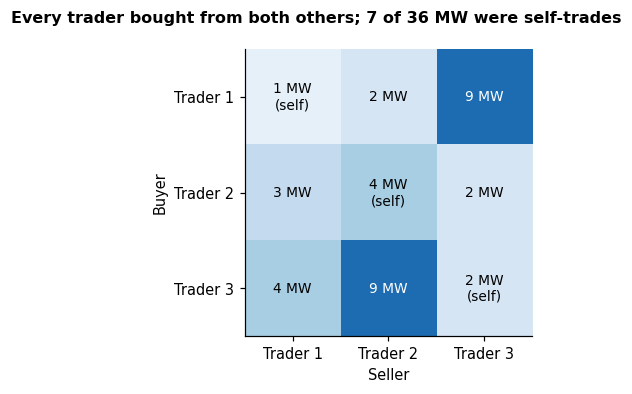

In [10]:
vol = np.zeros((3, 3), dtype=int)  # ticks of 0.1 MW
for _, _, q, buyer, seller, _ in rows:
    vol[buyer - 1, seller - 1] += q
assert vol.sum() == rows[:, QTY].sum()
pairs = int((vol[~np.eye(3, dtype=bool)] > 0).sum())  # buyer-seller pairs of two different traders that traded
answer = "Every trader bought from both others" if pairs == 6 else f"{pairs} of the 6 buyer-seller pairs traded"
names = [f"Trader {t}" for t in TRADERS]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.imshow(vol, cmap="Blues", vmin=0, vmax=vol.max() * 1.3); ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{vol[i, j] / 10:g} MW" + ("\n(self)" if i == j else ""), ha="center", va="center", fontsize=9,
                color="white" if vol[i, j] > 0.6 * vol.max() else "black")
ax.set_xticks(range(3), names); ax.set_yticks(range(3), names)
ax.set_xlabel("Seller"); ax.set_ylabel("Buyer")
fig.suptitle(f"{answer}; {np.trace(vol) / 10:g} of {vol.sum() / 10:g} MW were self-trades",
             x=0.01, ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout()
plt.show()

Each row adds up to what that trader bought, and each column to what it sold. The diagonal cells are
counted in both, which is why a self-trade leaves the position unchanged.

## Recap

- Several traders trade against each other at book level: one `ContractBook`, one `agent_id` per trader.
- A trader sees its own orders and trades and the anonymous book. A trade row from `get_agent_trades` has
  no counterparty (as in OMIE) and no side (a gap of this version; OMIE reports the side).
- The book's trade records name the passive and the aggressive trader; the sign of the quantity gives the side
  (negative: the aggressor bought). A 10-line converter turns them into the rows `compute_agent_pnl` reads.
- Cash and positions sum to exactly zero over all traders, when added as whole numbers.
- OMIE's matching has no self-trade prevention (OQ-12, provisional): a trader can trade with itself,
  which moves neither money nor energy for that participant number. Market-abuse rules (REMIT) still
  forbid wash trades.

## Exercises

1. **Another day of trading.** Start a fresh book (`book.init()`) and send 60 random orders with
   `random_flow` and a new generator, `np.random.default_rng(1)`. Do the cash and the positions still
   sum to exactly zero?
   *Hint:* reuse `settlement_rows`, `exact_cash` and the bought-minus-sold sums. Each record adds to
   one trader exactly what it takes from another.
2. **Valuing the positions.** Value each trader's position at the price of the last trade, and add it
   to its cash. Do these values sum to zero too? Why?
   *Hint:* the positions sum to zero, so valued at one common price they sum to zero as well.
3. **Trader 3 leaves (optional).** Cancel every resting order of trader 3 with
   `book.cancel_order(state, order_id, side)`. What happens to the anonymous book, and to the sums?
   *Hint:* a cancellation removes resting orders; it does not touch the trades.

The solutions are in the collapsed cell at the end.

## Further reading

- [Sessions › Several participants](../docs/sessions.md#several-participants) and
  [Sessions › Self-trades](../docs/sessions.md#self-trades); [Sessions › Sizing `nTrades`](../docs/sessions.md#sizing-ntrades)
  for the size of the trade buffer.
- [The market model](../docs/market-model.md#price-time-priority-and-matching): price-time priority,
  anonymity and the absence of self-trade prevention.
- The evidence: [the market specification](../docs/omiecid/market-spec.md) and
  [the certificate](../docs/omiecid/certificate.md), whose gap table records that a trade's side is
  not reported to the participant. Scenarios
  [C03](../notebooks/certification/C03_priority_ties_and_ownership.ipynb) (priority ignores ownership)
  and [C12](../notebooks/certification/C12_settlement_cash_leg.ipynb) (the cash leg sums to zero) certify
  the behaviour shown here.
- Next tutorial: [T08 — The overseer's view](T08_overseers_view.ipynb). Previous:
  [T02 — Order types and matching](T02_order_types.ipynb).

## Solutions

In [11]:
# Solutions to the exercises (collapsed; expand to read).
# 1. A fresh book and 60 new random orders: the sums are exactly zero again.
s = random_flow(book.init(), np.random.default_rng(1), 60)
r = settlement_rows(s)
pos = {t: int(r[r[:, BUYER] == t, QTY].sum() - r[r[:, SELLER] == t, QTY].sum()) for t in TRADERS}
csh = {t: exact_cash(r, t) for t in TRADERS}
print(f"1. {len(r)} trades; positions (MW) {[p / 10 for p in pos.values()]}, "
      f"cash (EUR) {[f'{c / 4000:+.5f}' for c in csh.values()]}; sums {sum(pos.values())} and {sum(csh.values())}")

# 2. Position x last price, in the same whole units (ticks x cents), plus the cash: the total is zero again.
last_c = int(rows[-1, PRICE]) - ZERO  # cents per MWh of the last trade of the main book
value = {t: cash[t] + position[t] * last_c for t in TRADERS}  # units of 1/4000 EUR
print(f"2. at {last_c / 100:.2f} EUR/MWh: " + ", ".join(f"trader {t} {v / 4000:+.5f} EUR" for t, v in value.items())
      + f"; sum {sum(value.values())}")

# 3. Trader 3 cancels every resting order: its quotes leave the book; the trades and the sums do not change.
s = state
for o in book.get_agent_orders(s, 3):
    s = book.cancel_order(s, o.order_id, o.side)
print(f"3. trader 3 now rests {len(book.get_agent_orders(s, 3))} orders; "
      f"trade records unchanged: {np.array_equal(settlement_rows(s), rows)}")
show_book(s)

1. 37 trades; positions (MW) [11.0, -1.0, -10.0], cash (EUR) ['-143.17500', '+13.27500', '+129.90000']; sums 0 and 0
2. at 52.10 EUR/MWh: trader 1 +0.60000 EUR, trader 2 -0.32500 EUR, trader 3 -0.27500 EUR; sum 0


3. trader 3 now rests 0 orders; trade records unchanged: True
   ask   52.40 EUR/MWh   7.0 MW
   ask   52.30 EUR/MWh   4.0 MW
   -------------------------------
   bid   51.90 EUR/MWh   3.0 MW
   bid   51.70 EUR/MWh   3.0 MW
